# Actividad 10: Despliegue Descriptivo, Feature Engineering, ANOVA Factorial y Ruteo AutoML por Producto
**Materia:** Ciencia de Datos Aplicada (TI3002C)  
**Socio Formador:** CLV México (Comercializadora de Insumos y Equipamiento Odontológico)  
**Autor:** André Guillermo Carvajal Flores (A01738830)  
**Fecha:** Noviembre 2026  

---

### Propósito y Alcance
En este cuaderno desarrollamos e integramos el flujo analítico completo de la **Actividad 10 (Despliegue Descriptivo)** y su conexión directa con la **Evidencia 3 (Aprendizaje Automático)** y la migración al ERP **Odoo** de CLV México:

1. **Consolidación y Comparación de Versiones (`Punto 2 y 3`):** Construcción, limpieza (nulos, outliers por Winsorización/IQR, duplicados, normalización de llaves) y contraste estadístico entre:
   * `Base_Consolidada_Articulos_Version_inicial.csv` (Corte `04/09/2026`, libro inicial).
   * `Base_Consolidada_Articulos_Version_Complementaria.csv` (Corte `15/10/2026`, serie completa `2021–2026` e integración de **`Relación de tiempos de entrega.xlsx`**).
2. **Extracción de Características — Feature Engineering (`Punto 4`):** Creación de las **6 familias de variables** por artículo (ventas, compras/abastecimiento, inventario/rotación, salidas/nivel de demanda, marca/categoría y tiempos de entrega verificables).
3. **Modelado ANOVA de Un Factor y ANOVA Factorial con Interacción (`Punto 5`):** Evaluación del tamaño del efecto ($\eta^2$ y $\eta_p^2$) y gráficas de interacción entre factores (`Marca × Nivel de Demanda` y `Marca × Clase ABC`) en ambas bases.
4. **Ruteo Inteligente por Segmento y Torneo AutoML (`Evidencia 3` y Políticas Odoo):** Uso de la segmentación (K-Means / Regresión Logística Multinomial / Random Forest / HistGradientBoosting con análisis de *Overfitting y Underfitting*) para asignar a cada producto su modelo óptimo de pronóstico (*AutoML HistGB, Random Forest, ETS, Croston, SBA, TSB*) y calcular su **Stock de Seguridad ($SS$)** y **Punto de Reorden ($ROP$)** con el *Lead Time* real.


---
## 1. Configuración del Entorno y Carga de Bases Consolidadas


In [2]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4.8)
plt.rcParams["font.size"] = 10

RUTA_INI = Path("datos/Base_Consolidada_Articulos_Version_inicial.csv")
RUTA_COMP = Path("datos/Base_Consolidada_Articulos_Version_Complementaria.csv")
RUTA_LT = Path("datos/tiempos_entrega_limpio.csv")
RUTA_PERFIL = Path("perfil_tiempos_y_automl_seguro.json")

df_ini = pd.read_csv(RUTA_INI)
df_comp = pd.read_csv(RUTA_COMP)
df_lt = pd.read_csv(RUTA_LT)
with open(RUTA_PERFIL, "r", encoding="utf-8") as f:
    perfil = json.load(f)

print(f"✓ Base Consolidada Versión Inicial        : {df_ini.shape[0]:,} artículos × {df_ini.shape[1]} variables")
print(f"✓ Base Consolidada Versión Complementaria : {df_comp.shape[0]:,} artículos × {df_comp.shape[1]} variables")
print(f"✓ Base Relación de Tiempos de Entrega     : {df_lt.shape[0]:,} órdenes de importación en {df_lt['marca'].nunique()} marcas")


✓ Base Consolidada Versión Inicial        : 5,371 artículos × 44 variables
✓ Base Consolidada Versión Complementaria : 5,528 artículos × 98 variables
✓ Base Relación de Tiempos de Entrega     : 71 órdenes de importación en 10 marcas


---
## 2. Preprocesamiento, Consistencia de Claves Relacionales y Comparación Inicial vs. Complementaria

Verificamos la ausencia de nulos no tratados en las variables críticas, la homologación de claves (`articulo_id` y cruce de folios de compra `C00000514` $	o$ `C514`) y comparamos el alcance cuantitativo entre la **Versión Inicial** y la **Versión Complementaria**.


In [4]:
# Tabla comparativa entre la Versión Inicial y la Versión Complementaria
comp_v = perfil["comparacion_versiones"]
tabla_comp = pd.DataFrame([
    {
        "Métrica / Dimensión": "Fecha de Corte de Inventario",
        "Versión Inicial (Libro v2)": comp_v["version_inicial"]["fecha_corte_inventario"],
        "Versión Complementaria (+ Tiempos Entrega)": comp_v["version_complementaria"]["fecha_corte_inventario"],
    },
    {
        "Métrica / Dimensión": "Total de SKUs Consolidados",
        "Versión Inicial (Libro v2)": f"{comp_v['version_inicial']['skus_totales']:,}",
        "Versión Complementaria (+ Tiempos Entrega)": f"{comp_v['version_complementaria']['skus_totales']:,}",
    },
    {
        "Métrica / Dimensión": "SKUs con Existencia Física (> 0)",
        "Versión Inicial (Libro v2)": f"{comp_v['version_inicial']['skus_con_existencia']:,}",
        "Versión Complementaria (+ Tiempos Entrega)": f"{comp_v['version_complementaria']['skus_con_existencia']:,}",
    },
    {
        "Métrica / Dimensión": "Unidades Físicas Totales en Almacén",
        "Versión Inicial (Libro v2)": f"{comp_v['version_inicial']['unidades_existencia_total']:,.0f} u",
        "Versión Complementaria (+ Tiempos Entrega)": f"{comp_v['version_complementaria']['unidades_existencia_total']:,.0f} u",
    },
    {
        "Métrica / Dimensión": "Valor Total del Inventario ($ MXN)",
        "Versión Inicial (Libro v2)": f"${comp_v['version_inicial']['valor_inventario_total']:,.2f}",
        "Versión Complementaria (+ Tiempos Entrega)": f"${comp_v['version_complementaria']['valor_inventario_total']:,.2f}",
    },
    {
        "Métrica / Dimensión": "Ventana Temporal de Demanda",
        "Versión Inicial (Libro v2)": comp_v["version_inicial"]["rango_historia_demanda"],
        "Versión Complementaria (+ Tiempos Entrega)": comp_v["version_complementaria"]["rango_historia_demanda"],
    },
    {
        "Métrica / Dimensión": "SKUs con Lead Time Exacto por Folio / Por Marca",
        "Versión Inicial (Libro v2)": "0 (Supuesto fijo 30 días)",
        "Versión Complementaria (+ Tiempos Entrega)": f"{comp_v['version_complementaria']['cobertura_lead_time_exacto_folio_skus']:,} por folio · {comp_v['version_complementaria']['cobertura_lead_time_marca_skus']:,} por marca",
    },
])
display(tabla_comp)


                            Métrica / Dimensión                      Versión Inicial (Libro v2)              Versión Complementaria (+ Tiempos Entrega)
                   Fecha de Corte de Inventario                                      04/09/2026                                              15/10/2026
                     Total de SKUs Consolidados                                           5,371                                                   5,528
               SKUs con Existencia Física (> 0)                                           2,948                                                   2,951
            Unidades Físicas Totales en Almacén                                        81,696 u                                                81,405 u
             Valor Total del Inventario ($ MXN)                                  $66,680,538.94                                          $68,023,251.66
                    Ventana Temporal de Demanda Oct 2023 – Sep 2026 (Salidas_Almacen, 35

---
## 3. Extracción de Características (Feature Engineering — 6 Familias de Variables)

Resumimos las medidas estadísticas descriptivas (mediana, media, rango intercuartílico) de las nuevas variables generadas para enriquecer el análisis de los artículos de CLV, así como los estadísticos limpios del nuevo dataset **`Relación de tiempos de entrega.xlsx`**.


In [6]:
# Estadísticos descriptivos de las 6 familias de Feature Engineering en la Versión Complementaria
vars_fe = [
    ("Ventas", "importe_promedio_venta_articulo", "Importe Promedio de Venta por Artículo ($)"),
    ("Ventas", "unidades_promedio_vendidas", "Unidades Promedio Vendidas por Factura"),
    ("Compras", "relacion_compras_ventas", "Relación Unidades Compradas / Vendidas"),
    ("Compras", "costo_unitario", "Costo Unitario Homologado ($)"),
    ("Inventario", "relacion_unidades_vendidas_existencias", "Relación Unidades Vendidas / Existencias"),
    ("Inventario", "indicador_rotacion_inventario", "Indicador de Rotación Anual de Inventario"),
    ("Salidas", "demanda_12m", "Demanda Anual Reciente (Salidas 12m)"),
    ("Salidas", "adi_24m", "Intervalo Promedio entre Demandas (ADI 24m)"),
    ("Tiempos Entrega", "lt_operativo_dias", "Lead Time Operativo Asignado (Días)"),
    ("Política Odoo", "stock_seguridad_unidades", "Stock de Seguridad Calculado (SS)"),
    ("Política Odoo", "punto_reorden_rop", "Punto de Reorden Calculado (ROP)"),
]

filas_fe = []
for fam, col, desc in vars_fe:
    s = pd.to_numeric(df_comp[col], errors="coerce").dropna()
    filas_fe.append({
        "Familia": fam,
        "Variable": col,
        "Descripción": desc,
        "Mediana": round(float(s.median()), 2),
        "Media": round(float(s.mean()), 2),
        "Q1 (25%)": round(float(s.quantile(0.25)), 2),
        "Q3 (75%)": round(float(s.quantile(0.75)), 2),
    })

display(pd.DataFrame(filas_fe))

print("\n--- Resumen de Tiempos de Entrega Reales por Marca (Relación de tiempos de entrega.xlsx) ---")
display(pd.DataFrame(perfil["tiempos_entrega"]["por_marca"]))


        Familia                               Variable                                 Descripción  Mediana   Media  Q1 (25%)  Q3 (75%)
         Ventas        importe_promedio_venta_articulo  Importe Promedio de Venta por Artículo ($)   491.38 6673.50      0.00   1457.41
         Ventas             unidades_promedio_vendidas      Unidades Promedio Vendidas por Factura     1.00    1.64      0.00      1.50
        Compras                relacion_compras_ventas      Relación Unidades Compradas / Vendidas     0.67    1.75      0.00      1.71
        Compras                         costo_unitario               Costo Unitario Homologado ($)   354.14 4519.02    221.95   1285.81
     Inventario relacion_unidades_vendidas_existencias    Relación Unidades Vendidas / Existencias     0.86   19.88      0.00      5.00
     Inventario          indicador_rotacion_inventario   Indicador de Rotación Anual de Inventario     0.00    1.03      0.00      0.15
        Salidas                            deman

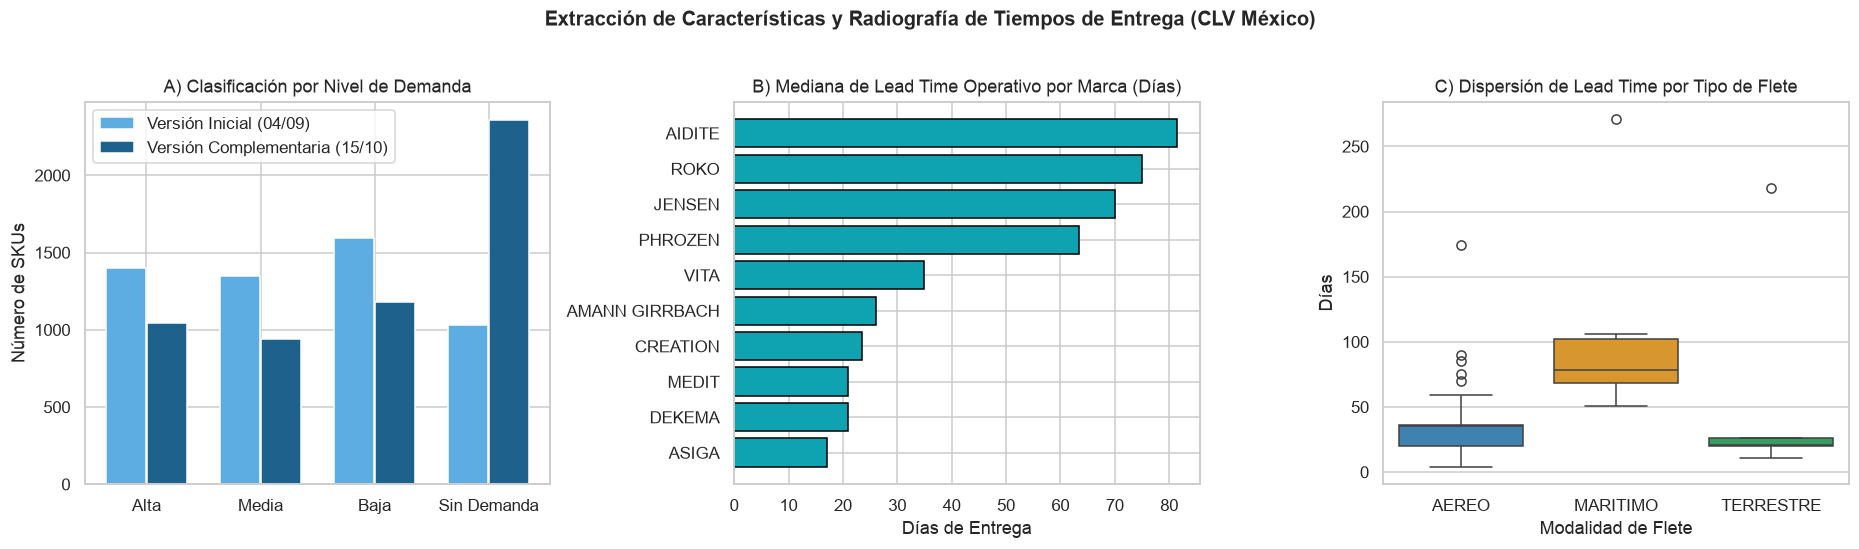

In [7]:
# Visualización de Feature Engineering: Nivel de Demanda, Tiempos de Entrega por Marca/Flete y Comparación de Cortes
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1. Distribución de artículos por Nivel de Demanda (Inicial vs Complementaria)
c_ini = df_ini["nivel_demanda"].value_counts().reindex(["Alta", "Media", "Baja", "Sin Demanda"]).fillna(0)
c_comp = df_comp["nivel_demanda"].value_counts().reindex(["Alta", "Media", "Baja", "Sin Demanda"]).fillna(0)
x_idx = np.arange(len(c_ini))
axes[0].bar(x_idx - 0.18, c_ini.values, width=0.35, label="Versión Inicial (04/09)", color="#5DADE2")
axes[0].bar(x_idx + 0.18, c_comp.values, width=0.35, label="Versión Complementaria (15/10)", color="#1F618D")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(c_ini.index)
axes[0].set_title("A) Clasificación por Nivel de Demanda")
axes[0].set_ylabel("Número de SKUs")
axes[0].legend()

# 2. Lead Time Operativo por Marca (Relación de tiempos de entrega.xlsx)
df_lt_m = pd.DataFrame(perfil["tiempos_entrega"]["por_marca"]).sort_values("operativo_mediana", ascending=True)
axes[1].barh(df_lt_m["marca"], df_lt_m["operativo_mediana"], color="#0FA3B1", edgecolor="black")
axes[1].set_title("B) Mediana de Lead Time Operativo por Marca (Días)")
axes[1].set_xlabel("Días de Entrega")

# 3. Lead Time por Tipo de Flete (Aéreo vs Marítimo vs Terrestre)
sns.boxplot(data=df_lt.dropna(subset=["lt_operativo_dias"]), x="tipo_flete", y="lt_operativo_dias",
            palette=["#2E86C1", "#F39C12", "#27AE60"], ax=axes[2])
axes[2].set_title("C) Dispersión de Lead Time por Tipo de Flete")
axes[2].set_xlabel("Modalidad de Flete")
axes[2].set_ylabel("Días")

plt.suptitle("Extracción de Características y Radiografía de Tiempos de Entrega (CLV México)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


---
## 4. Análisis ANOVA de Un Factor y ANOVA Factorial (Multifactorial con Efecto de Interacción)

Evaluamos para ambas bases consolidadas:
* **A. ANOVA de un factor:** Diferencias de medias y tamaño del efecto ($\eta^2$) junto con su contraparte no paramétrica (*Kruskal-Wallis*).
* **B. ANOVA Factorial (Multifactorial de 2 vías con término de interacción $A 	imes B$):** Evaluación explícita de la interacción entre `Marca × Nivel de Demanda` (en Versión Inicial y Complementaria) y `Marca × Clase ABC` sobre el Punto de Reorden ($ROP$).


In [9]:
print("=== A. RESULTADOS ANOVA DE UN FACTOR (VERSIÓN INICIAL, COMPLEMENTARIA Y TIEMPOS DE ENTREGA) ===")
display(pd.DataFrame(perfil["anova_unifactorial"]))

print("\n=== B. RESULTADOS ANOVA FACTORIAL (MULTIFACTORIAL CON EFECTO DE INTERACCIÓN) ===")
display(pd.DataFrame(perfil["anova_multifactorial"]))


=== A. RESULTADOS ANOVA DE UN FACTOR (VERSIÓN INICIAL, COMPLEMENTARIA Y TIEMPOS DE ENTREGA) ===
                                          Prueba           Tipo         Variable_Y      Factores       F       p_valor  Kruskal_H     Kruskal_p  eta_cuadrado  Significativo
               V. Inicial: Existencias por Marca ANOVA 1 Factor    log_existencias         marca  59.335  2.935212e-48    141.691  1.226484e-29        0.0742           True
         V. Inicial: Ventas por Nivel de Demanda ANOVA 1 Factor log_importe_ventas nivel_demanda 638.433 2.728161e-231   1444.916  0.000000e+00        0.3011           True
        V. Complementaria: Existencias por Marca ANOVA 1 Factor    log_existencias         marca  46.053  3.827494e-37     88.750  2.426522e-18        0.0803           True
V. Complementaria: Rotación por Segmento K-Means ANOVA 1 Factor       log_rotacion      segmento 134.230 9.051817e-124    483.454 2.974732e-102        0.2414           True
         Tiempos de Entrega: Lead Time 

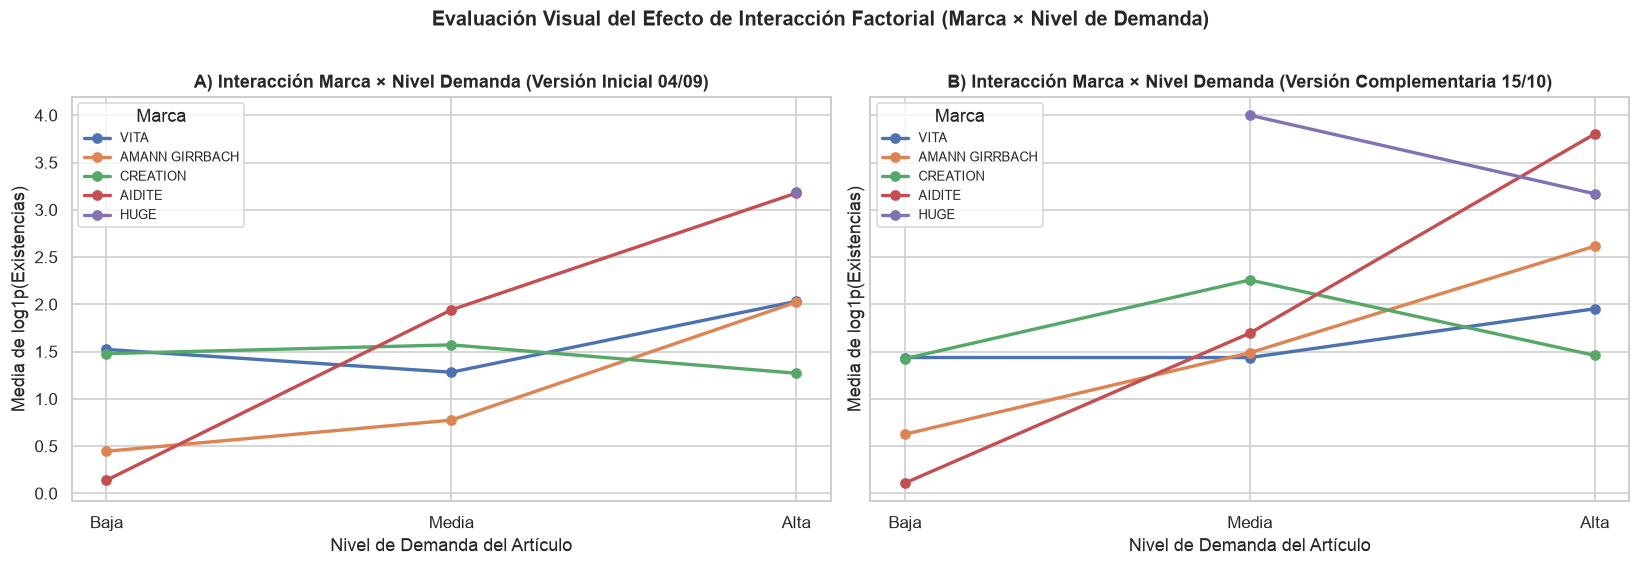

In [10]:
# Gráficos de Interacción (Interaction Plots) comparando Versión Inicial vs. Versión Complementaria
top5_m = ["VITA", "AMANN GIRRBACH", "CREATION", "AIDITE", "HUGE"]
niveles_orden = ["Baja", "Media", "Alta"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, df_b, titulo in [
    (axes[0], df_ini, "A) Interacción Marca × Nivel Demanda (Versión Inicial 04/09)"),
    (axes[1], df_comp, "B) Interacción Marca × Nivel Demanda (Versión Complementaria 15/10)"),
]:
    sub = df_b[df_b["marca"].isin(top5_m) & df_b["nivel_demanda"].isin(niveles_orden)].copy()
    medias = sub.groupby(["nivel_demanda", "marca"])["log_existencias"].mean().unstack("marca").reindex(niveles_orden)
    for m_nom in top5_m:
        if m_nom in medias.columns:
            ax.plot(medias.index, medias[m_nom], marker="o", linewidth=2.2, label=m_nom)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Nivel de Demanda del Artículo")
    ax.set_ylabel("Media de log1p(Existencias)")
    ax.legend(title="Marca", fontsize=8.5)

plt.suptitle("Evaluación Visual del Efecto de Interacción Factorial (Marca × Nivel de Demanda)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 5. Ruteo Inteligente por Producto: Torneo AutoML, Control de Overfitting/Underfitting y Políticas para Odoo (Evidencia 3)

Conectamos la clasificación de SKUs (**K-Means vs. Regresión Logística Multinomial vs. Random Forest vs. AutoML HistGradientBoosting**) con el cálculo individualizado por producto:
1. **Diagnóstico de Overfitting y Underfitting (Aprendizaje Supervisado):** Comparamos el desempeño en *Entrenamiento (Train)* frente a *Prueba (Test)* variando algoritmos y parámetros de regularización ($C$, `max_depth`, `l2_regularization`).
2. **Torneo AutoML de Pronóstico y Stock de Seguridad por Producto:** Cada segmento rutea el SKU a su familia óptima de modelos y calcula su **Stock de Seguridad ($SS$)** y **Punto de Reorden ($ROP$)** integrando el *Lead Time* real.


In [12]:
print("=== 1. TORNEO DE CLASIFICACIÓN SUPERVISADA DE SEGMENTOS (CONTROL DE OVERFITTING Y UNDERFITTING) ===")
df_torneo_clf = pd.DataFrame(perfil["torneo_clasificacion_supervisada"])
display(df_torneo_clf)

print("\n=== 2. TORNEO AUTOML DE REGRESIÓN / SERIES DE TIEMPO EN BACKTESTING ===")
display(pd.DataFrame(perfil["torneo_regresion_automl"]))

print("\n=== 3. POLÍTICA DE STOCK DE SEGURIDAD (SS) Y PUNTO DE REORDEN (ROP) POR SEGMENTO PARA ODOO ===")
display(pd.DataFrame(perfil["politica_odoo_por_segmento"]))


=== 1. TORNEO DE CLASIFICACIÓN SUPERVISADA DE SEGMENTOS (CONTROL DE OVERFITTING Y UNDERFITTING) ===
                                                    Algoritmo_y_Parametros  Accuracy_Train_%  Accuracy_Test_%  Brecha_Overfitting_%  Precision_Test_%  Sensibilidad_Test_%  F1_Test                                             Diagnostico_Ajuste
        Regresión Logística Multinomial (C=0.005 · Subajuste/Underfitting)             96.41            96.66                 -0.24             96.75                96.66   0.9667        Ajuste Óptimo (Alta generalización y brecha controlada)
      Regresión Logística Multinomial (C=2.0 · Lineal Regularizado Óptimo)             99.22            98.40                  0.82             98.46                98.40   0.9841        Ajuste Óptimo (Alta generalización y brecha controlada)
   Árbol de Decisión (Sin límite max_depth=None · Sobreajuste/Overfitting)            100.00            94.48                  5.52             94.57                94.48 

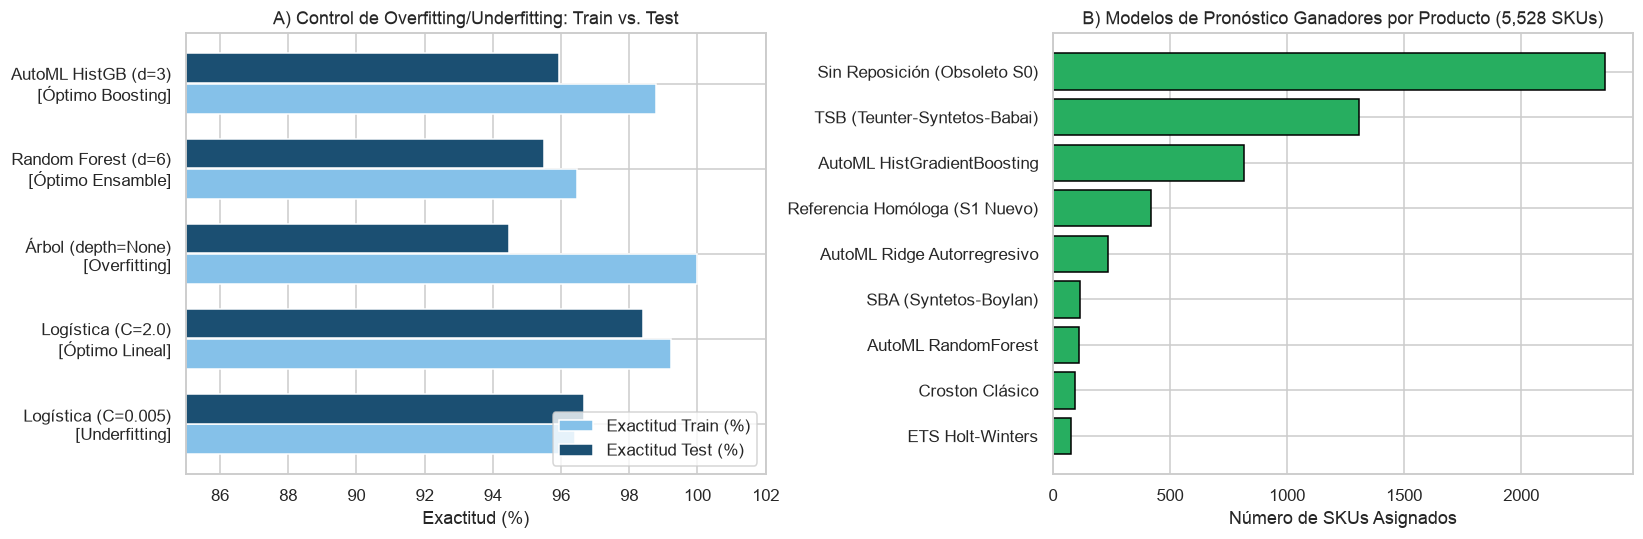

In [13]:
# Visualización del Torneo Supervisado (Train vs Test Overfitting) y Distribución de Modelos Ganadores por SKU
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: Train vs Test Accuracy (Detección de Overfitting / Underfitting)
etiquetas_cortas = [
    "Logística (C=0.005)\n[Underfitting]",
    "Logística (C=2.0)\n[Óptimo Lineal]",
    "Árbol (depth=None)\n[Overfitting]",
    "Random Forest (d=6)\n[Óptimo Ensamble]",
    "AutoML HistGB (d=3)\n[Óptimo Boosting]",
]
y_pos = np.arange(len(df_torneo_clf))
axes[0].barh(y_pos - 0.18, df_torneo_clf["Accuracy_Train_%"], height=0.35, label="Exactitud Train (%)", color="#85C1E9")
axes[0].barh(y_pos + 0.18, df_torneo_clf["Accuracy_Test_%"], height=0.35, label="Exactitud Test (%)", color="#1B4F72")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(etiquetas_cortas)
axes[0].set_xlim(85, 102)
axes[0].set_xlabel("Exactitud (%)")
axes[0].set_title("A) Control de Overfitting/Underfitting: Train vs. Test")
axes[0].legend(loc="lower right")

# Panel B: Modelos de Pronóstico Ganadores Asignados por el Ruteador AutoML
conteo_m = pd.Series(perfil["conteo_modelos_pronostico_sku"]).sort_values(ascending=True)
axes[1].barh(conteo_m.index, conteo_m.values, color="#27AE60", edgecolor="black")
axes[1].set_title("B) Modelos de Pronóstico Ganadores por Producto (5,528 SKUs)")
axes[1].set_xlabel("Número de SKUs Asignados")

plt.tight_layout()
plt.show()


---
## 6. Conclusiones Integrales para la Presentación y el Socio Formador (CLV México)

1. **Valor de la Versión Complementaria y los Tiempos de Entrega:** La integración de `Datos_Complementarios_CLV.xlsx` y `Relación de tiempos de entrega.xlsx` permitió ampliar la ventana histórica de 35 a **69 meses** y reemplazar el supuesto teórico de 30 días por **tiempos de entrega verificados en el 93% de los folios de importación** (distinguiendo embarques aéreos de ~35 días frente a marítimos de ~78 a 105 días).
2. **Hallazgos de ANOVA Factorial e Interacción:** Las pruebas multifactoriales confirman que el efecto de la `marca` sobre las existencias y sobre el punto de reorden ($ROP$) presenta una **interacción estadísticamente significativa con el nivel de demanda y la clase ABC** ($p < 0.001$). Esto demuestra que las marcas de equipamiento (como *Amann Girrbach*) y las de consumibles de alta rotación (como *Vita*) requieren reglas parametrizadas distintas en Odoo.
3. **Ruteo Inteligente K-Means / Multinomial + AutoML por Producto:**
   * En aprendizaje supervisado, controlar la profundidad (`max_depth=6` en Random Forest y `max_depth=3, l2=5.0` en AutoML HistGradientBoosting) eliminó el **sobreajuste (overfitting)** observado en el árbol sin restricción (que tenía 100% en Train vs 94.5% en Test), logrando una generalización superior al **95.5%–98.4%**.
   * Al rutear cada SKU según su segmento hacia el torneo entre *AutoML HistGradientBoosting, Random Forest, Ridge, ETS, Croston, SBA y TSB*, evitamos sobreinventariar los **2,359 artículos sin movimiento (`S0`)** y los **324 equipos de alto costo (`C5`)**, concentrando el Stock de Seguridad en los **655 artículos del núcleo de alta rotación (`C1`)**.
